# LDA vs. Logistic Regression: Same Boundary, Different Bets

**DSAI 621 — Week 3.** LDA and logistic regression fit exactly the same kind of classifier: the
log-odds is linear in $x$, so the boundary is a straight line (a hyperplane when $p > 2$). They
estimate it differently. Logistic regression maximizes the conditional likelihood of $Y$ given
$x$ and assumes nothing about $X$. LDA assumes that $X$ for each class is Gaussian with a shared covariance
matrix, estimates the means and the covariance, and plugs them into Bayes' theorem. In this
lab you find out what LDA's extra assumption buys when it's true, what it costs when it's false,
and which method wins on real data.

The first time something new appears, the notebook gives you all of the code. When a step
repeats something you've already seen, you write it, and the cell says `# TODO`. Short
exercises marked **E1**, **E2**, … ask you to stop and look at what you just made.

A companion lab, `qda_vs_naive_bayes.ipynb`, runs the same five sections for QDA and naive
Bayes.

In [4]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.datasets import load_breast_cancer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(621)

### Helper functions

You'll use these four functions in every section; read them, but you don't need to change them.

- `make_gaussian(n, mu0, mu1, Sigma, rng)` draws $n$ observations with equal priors:
  $Y \in \{0, 1\}$, then $X \mid Y = k \sim N(\mu_k, \Sigma_k)$. `Sigma` is either one matrix
  (shared by both classes) or a pair of matrices, one per class.
- `simulation(make_data)` turns a data generator into a *draw* function: each call returns a
  fresh training set of size $n$, plus one large test set that stays fixed.
- `learning_curve(draw, models, ns)` fits every model to `reps` training sets of each size $n$
  and records the average test error. If a model can't be fitted on some training set, its
  error at that $n$ is `NaN` and the `failed` column counts how often.
- `plot_curves(curve)` plots test error against $n$ (log scale), one line style per model.

In [5]:
def make_gaussian(n, mu0, mu1, Sigma, rng):
    "Equal priors; X | Y=k ~ N(mu_k, Sigma_k). Sigma is one matrix (shared) or a pair."
    Sigmas = Sigma if isinstance(Sigma, (list, tuple)) else (Sigma, Sigma)
    y = rng.integers(0, 2, n)
    X = np.empty((n, len(mu0)))
    for k, (mu, S) in enumerate([(mu0, Sigmas[0]), (mu1, Sigmas[1])]):
        X[y == k] = rng.multivariate_normal(mu, S, size=np.sum(y == k))
    return X, y


def simulation(make_data, n_test=20_000, seed=0):
    "A draw(n, rng) function: a new training set each call, and one fixed test set."
    X_te, y_te = make_data(n_test, np.random.default_rng(seed))
    def draw(n, rng):
        X, y = make_data(n, rng)
        return X, y, X_te, y_te
    return draw


def learning_curve(draw, models, ns, reps=200, seed=1):
    "Average test error of each model over `reps` training sets of each size n."
    rng = np.random.default_rng(seed)
    rows = []
    for n in ns:
        for _ in range(reps):
            X, y, X_te, y_te = draw(n, rng)
            for name, make_model in models.items():
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")   # e.g. convergence warnings on separable data
                    try:
                        err = np.mean(make_model().fit(X, y).predict(X_te) != y_te)
                    except (np.linalg.LinAlgError, ValueError):
                        err = np.nan                  # the model can't be fitted to this sample
                rows.append((name, n, err))
    df = pd.DataFrame(rows, columns=["model", "n", "error"])
    return (df.groupby(["n", "model"])["error"]
              .agg(error=lambda e: e.mean(skipna=False), failed=lambda e: e.isna().sum())
              .reset_index())


STYLES = {"LDA": "o-", "logistic": "s--", "QDA": "^-.", "naive Bayes": "D:"}

def plot_curves(curve, title, bayes=None, ax=None):
    "Test error against n, one line style per model; a dotted line at the Bayes error."
    ax = ax or plt.subplots(figsize=(7, 4))[1]
    for name, d in curve.groupby("model"):
        ax.plot(d["n"], d["error"], STYLES.get(name, "x-"), label=name, lw=1.8, ms=6)
    if bayes is not None:
        ax.axhline(bayes, color="grey", ls=":", label="Bayes error")
    ax.set(xscale="log", xlabel="training size n (log scale)", ylabel="test error", title=title)
    ax.minorticks_off()
    ax.set_xticks(sorted(curve["n"].unique()), labels=sorted(curve["n"].unique()))
    ax.legend()
    return ax


def table(curve):
    "One row per n, one column per model."
    return curve.pivot(index="n", columns="model", values="error").round(3)

---
## 1. One boundary, two ways to estimate it

Start with two Gaussian classes in two dimensions that share a covariance matrix, so LDA's
assumption is exactly right:

$$\mu_0 = (0, 0), \quad \mu_1 = (1, 1.5), \quad \Sigma = \begin{pmatrix} 1 & 0.7 \\ 0.7 & 1 \end{pmatrix}, \quad \pi_0 = \pi_1 = 0.5 .$$

Classes are labelled 0 and 1, as scikit-learn does. With $\pi_k$ the prior and $\Sigma$ shared,
the log-odds of class 1 is (lecture, §2.2; ESL 4.9)

$$\log\frac{\Pr(Y = 1 \mid X = x)}{\Pr(Y = 0 \mid X = x)} = \underbrace{\log\frac{\pi_1}{\pi_0} - \tfrac12(\mu_1 + \mu_0)^T\Sigma^{-1}(\mu_1 - \mu_0)}_{\beta_0} + x^T\underbrace{\Sigma^{-1}(\mu_1 - \mu_0)}_{\beta} .$$

Logistic regression fits $\beta_0 + x^T\beta$ directly. `C=np.inf` turns off scikit-learn's
default ridge penalty, so this is the maximum likelihood fit from DSAI 601.

In [6]:
mu0, mu1 = np.array([0.0, 0.0]), np.array([1.0, 1.5])
Sigma = np.array([[1.0, 0.7], [0.7, 1.0]])

X, y = make_gaussian(100, mu0, mu1, Sigma, rng)
lda = LinearDiscriminantAnalysis(store_covariance=True).fit(X, y)
logit = LogisticRegression(C=np.inf).fit(X, y)

print("LDA:      intercept", lda.intercept_.round(3), " slopes", lda.coef_.round(3))
print("logistic: intercept", logit.intercept_.round(3), " slopes", logit.coef_.round(3))

LDA:      intercept [-1.472]  slopes [[-0.407  1.855]]
logistic: intercept [-1.49]  slopes [[-0.49   1.889]]


LDA never fits $\beta$ directly: it estimates $\pi_k$, $\mu_k$ and $\Sigma$, and $\beta_0$ and
$\beta$ follow from the formula above. Check that. Compute $\hat\beta$ and $\hat\beta_0$ from
`lda.priors_`, `lda.means_` (row $k$ is $\hat\mu_k$) and `lda.covariance_`, and confirm with
`np.allclose` that they equal `lda.coef_[0]` and `lda.intercept_[0]`. Use
`np.linalg.solve(S, v)` for $S^{-1}v$.

(scikit-learn's pooled covariance divides by $n$ rather than the $n - K$ in the lecture notes.
That changes $\hat\Sigma$ by a factor of $98/100$ here, and the boundary only slightly.)

In [7]:
pi_hat, mu_hat, S_hat = lda.priors_, lda.means_, lda.covariance_
# TODO: compute beta_hat and beta0_hat from the formula above, then check them against
# lda.coef_[0] and lda.intercept_[0] with np.allclose

The true $\beta_0$ and $\beta$ come from the same formula with the true parameters. Each
classifier's boundary is the line $\beta_0 + \beta_1x_1 + \beta_2x_2 = 0$, that is,
$x_2 = -(\beta_0 + \beta_1x_1)/\beta_2$. The next cell draws the true boundary and the two
fitted ones over the training data.

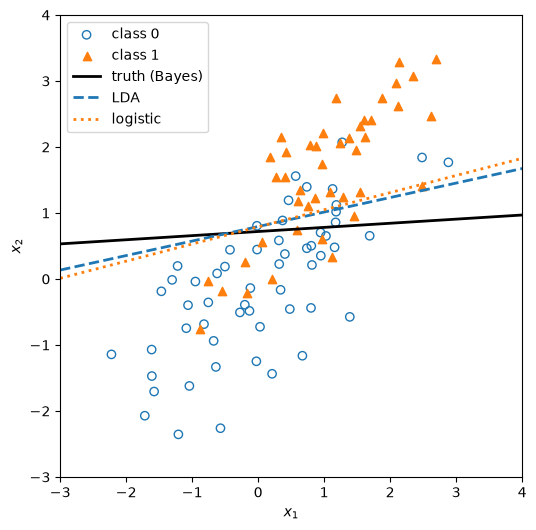

,truth (Bayes),LDA,logistic
beta0,-1.127,-1.472,-1.490
beta1,-0.098,-0.407,-0.490
beta2,1.569,1.855,1.889


In [8]:
beta_true = np.linalg.solve(Sigma, mu1 - mu0)
beta0_true = -0.5 * (mu1 + mu0) @ beta_true          # log(pi1/pi0) = 0

lines = {
    "truth (Bayes)": (beta0_true, beta_true, "k-"),
    "LDA": (lda.intercept_[0], lda.coef_[0], "--"),
    "logistic": (logit.intercept_[0], logit.coef_[0], ":"),
}

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*X[y == 0].T, marker="o", facecolors="none", edgecolors="tab:blue", label="class 0")
ax.scatter(*X[y == 1].T, marker="^", color="tab:orange", label="class 1")
x1 = np.linspace(-3, 4, 2)
for name, (b0, b, style) in lines.items():
    ax.plot(x1, -(b0 + b[0] * x1) / b[1], style, lw=2, label=name)
ax.set(xlim=(-3, 4), ylim=(-3, 4), xlabel="$x_1$", ylabel="$x_2$", aspect="equal")
ax.legend()
plt.show()

pd.DataFrame({name: [b0, *b] for name, (b0, b, _) in lines.items()},
             index=["beta0", "beta1", "beta2"]).round(3)

**E1.** Are the two fitted boundaries the same line? Which coefficients are closer to the
truth for this sample? Why can't one training set settle which method is better?

---
## 2. LDA's home turf: the classes really are Gaussian

To compare the methods fairly, average over many training sets. Take $p = 5$ predictors,
$\Sigma = I$, and means that differ only in the first coordinate,
$\mu_1 - \mu_0 = (3, 0, 0, 0, 0)$. With equal priors the Bayes classifier errs with
probability $\Phi(-\Delta/2)$, where $\Delta = 3$ is the distance between the means in units of
the standard deviation. (Only $x_1$ carries information, so this is the one-predictor
calculation from the lecture, §2.3, with the boundary at $x_1 = 1.5$.)

`models` maps a name to a function that builds a fresh, unfitted model. `learning_curve`
calls it once for every training set.

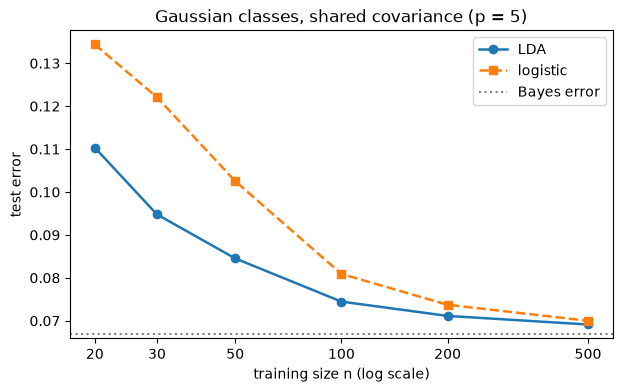

Bayes error 0.067


model,LDA,logistic
n,,
20,0.110,0.134
30,0.095,0.122
50,0.085,0.103
100,0.074,0.081
200,0.071,0.074
500,0.069,0.070


In [9]:
p = 5
mu0_5, mu1_5 = np.zeros(p), np.r_[3.0, np.zeros(p - 1)]
bayes_5 = norm.cdf(-3 / 2)

def make_lda_world(n, rng):
    return make_gaussian(n, mu0_5, mu1_5, np.eye(p), rng)

models = {
    "LDA": lambda: LinearDiscriminantAnalysis(),
    "logistic": lambda: LogisticRegression(C=np.inf, max_iter=1000),
}
ns = [20, 30, 50, 100, 200, 500]

curve_lda_world = learning_curve(simulation(make_lda_world), models, ns)
plot_curves(curve_lda_world, "Gaussian classes, shared covariance (p = 5)", bayes=bayes_5)
plt.show()
print(f"Bayes error {bayes_5:.3f}")
table(curve_lda_world)

The test error can't go below the Bayes error, so what each method controls is its **excess
error**, test error minus Bayes error: the price of estimating the boundary from $n$
observations.

In [10]:
excess = table(curve_lda_world) - bayes_5
excess["logistic / LDA"] = (excess["logistic"] / excess["LDA"]).round(2)
excess.round(3)

model,LDA,logistic,logistic / LDA
n,,,
20,0.043,0.067,1.56
30,0.028,0.055,1.96
50,0.018,0.036,1.99
100,0.007,0.014,1.97
200,0.004,0.007,1.72
500,0.002,0.003,1.46


**E2.** Which method has the lower test error at every $n$? Roughly how many times larger is
logistic regression's excess error than LDA's? Does the ratio shrink as $n$ grows?

**E3.** Both methods converge to the same boundary as $n \to \infty$. In one sentence, why is
LDA's estimate less variable when its assumption is true? (Think about which observations
each method's estimate depends on.)

Part of logistic regression's trouble at small $n$ is that the training data are often
*perfectly separable*: a hyperplane classifies every training point correctly, and then the
maximum likelihood estimate doesn't exist (DSAI 601, §3.5). The next cell counts how often
that happens. On separable data, logistic regression's training error is 0.

In [11]:
check = np.random.default_rng(2)
for n in [20, 30, 50, 100, 200]:
    sep = 0
    for _ in range(200):
        X_s, y_s = make_lda_world(n, check)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit = LogisticRegression(C=np.inf, max_iter=1000).fit(X_s, y_s)
        sep += fit.score(X_s, y_s) == 1.0
    print(f"n = {n:3d}: {sep / 200:5.0%} of training sets perfectly separated")

n =  20:   96% of training sets perfectly separated
n =  30:   80% of training sets perfectly separated
n =  50:   49% of training sets perfectly separated
n = 100:    6% of training sets perfectly separated
n = 200:    0% of training sets perfectly separated


---
## 3. Logistic regression's home turf: the classes aren't Gaussian

Keep everything from Section 2, but contaminate class 1: each class-1 observation, with
probability 0.1, is moved 10 units further along $x_1$, deep inside class 1's territory. These
points are easy to classify correctly, and the best boundary barely moves, because so few of
them fall near it. But class 1 is no longer Gaussian.

Write `make_outlier_world(n, rng)`: draw from `make_lda_world`, then add 10 to the first
coordinate of each class-1 row with probability 0.1 (use `rng.random(n) < 0.1`). Then run
`learning_curve` with the same `models` and `ns` and plot it. There's no simple formula for
this Bayes error, so leave out `bayes=`.

In [12]:
def make_outlier_world(n, rng):
    # TODO
    ...

# TODO: learning curve, plot and table, as in Section 2

To see what went wrong for LDA, fit both methods to one very large sample from each world.
With $n = 100{,}000$ there is almost no estimation noise left, so any difference is bias.
The boundary is where $\beta_0 + x^T\beta = 0$; since only $x_1$ matters here, compare where
each boundary crosses the $x_1$ axis, $-\beta_0/\beta_1$. (The Bayes boundary in the clean world
is at $x_1 = 1.5$, halfway between the means.)

In [13]:
big = np.random.default_rng(3)
rows = {}
for world, make in [("clean", make_lda_world), ("outliers", make_outlier_world)]:
    X_big, y_big = make(100_000, big)
    for name, make_model in models.items():
        m = make_model().fit(X_big, y_big)
        rows[(world, name)] = {"boundary at x1": -m.intercept_[0] / m.coef_[0, 0],
                               "beta1": m.coef_[0, 0]}
    lda_big = LinearDiscriminantAnalysis(store_covariance=True).fit(X_big, y_big)
    print(f"{world:8s}: class-1 mean of x1 = {lda_big.means_[1, 0]:.2f}, "
          f"pooled variance of x1 = {lda_big.covariance_[0, 0]:.2f}")
pd.DataFrame(rows).T.round(3)

clean   : class-1 mean of x1 = 3.00, pooled variance of x1 = 1.00


TypeError: cannot unpack non-iterable NoneType object

**E4.** How did the outliers change LDA's estimate of $\mu_1$ and of $\Sigma$? Where did that
move LDA's boundary, and which kind of error (class 0 called class 1, or the reverse) does it
make more of?

**E5.** Logistic regression's boundary barely moved. Why do points far from the boundary have
so little influence on the logistic fit? (Look at the logistic log-likelihood: what is a
far-away, correctly classified point's contribution, and its derivative?)

---
## 4. A breaking point: perfectly separated classes

Section 2 showed that small training sets are often separable. Take one such training set,
$n = 20$ from `make_lda_world`, and watch what happens to the logistic fit as the optimizer
runs for longer.

In [ ]:
sep_rng = np.random.default_rng(4)
while True:
    X20, y20 = make_lda_world(20, sep_rng)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if LogisticRegression(C=np.inf, max_iter=10_000).fit(X20, y20).score(X20, y20) == 1:
            break

for iters in [5, 20, 100, 1000, 10_000]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = LogisticRegression(C=np.inf, max_iter=iters).fit(X20, y20)
    p_hat = m.predict_proba(X20)[:, 1]
    print(f"max_iter = {iters:6d}:  |beta| = {np.linalg.norm(m.coef_):9.1f},  "
          f"fitted probabilities between {p_hat.min():.1e} and {p_hat.max():.6f}")

Now do the same comparison for LDA and for scikit-learn's *default* logistic regression,
`LogisticRegression()`, which has a ridge penalty with $C = 1$ (lecture 2). For each of the
three models, print $\|\hat\beta\|$ (`np.linalg.norm(m.coef_)`; the true $\|\beta\| = 3$) and,
on a large test sample from `make_lda_world`, the test error and the **log loss**
`log_loss(y_test, m.predict_proba(X_test))`. Log loss is the negative average log-likelihood
per observation, so it measures how good the *probabilities* are, not just the
classifications. A confident wrong answer costs a lot.

In [ ]:
X_test, y_test = make_lda_world(20_000, np.random.default_rng(5))
three = {
    "logistic, C = inf": LogisticRegression(C=np.inf, max_iter=10_000),
    "logistic, C = 1 (default)": LogisticRegression(),
    "LDA": LinearDiscriminantAnalysis(),
}
# TODO: fit each model to (X20, y20); print |beta|, and the test error and log loss
# on (X_test, y_test)

**E6.** What happens to $\|\hat\beta\|$ and to the fitted probabilities as `max_iter` grows?
What would happen with unlimited iterations, and why does the optimizer eventually stop anyway?

**E7.** The classes in this world overlap (the Bayes error is 6.7%), yet the unpenalized
logistic fit says its training points are certain. Which model has the worst test log loss,
and why is it so much worse than its test error suggests? Why does LDA have no trouble with
separable data?

---
## 5. Real data: breast cancer biopsies

The Wisconsin breast cancer data (Street, Wolberg and Mangasarian, 1993) ship with scikit-learn.
For 569 tumours, they record 30 measurements of the cell nuclei in a biopsy image, and whether
the tumour was malignant (212) or benign (357). We use the 8 "mean" measurements, leaving out
perimeter and area: they are almost exact functions of radius (correlation above 0.99), and
nearly collinear predictors make a covariance matrix close to singular.

Nothing here is simulated, so there's no Bayes error and no fixed test set. Instead, each
repetition draws a random training set of size $n$ and tests on the other $569 - n$ tumours.
We standardize inside a pipeline, so the scaling is learned from the training set only.

In [ ]:
cancer = load_breast_cancer(as_frame=True)
features = [c for c in cancer.data.columns[:10] if c not in ("mean perimeter", "mean area")]
X_bc = cancer.data[features].to_numpy()
y_bc = 1 - cancer.target.to_numpy()          # 1 = malignant, 0 = benign

def draw_cancer(n, rng):
    "A random training set of size n; the rest of the data is the test set."
    idx = rng.permutation(len(y_bc))
    return X_bc[idx[:n]], y_bc[idx[:n]], X_bc[idx[n:]], y_bc[idx[n:]]

print(features)
print(f"{len(y_bc)} tumours, {y_bc.sum()} malignant")

Run a learning curve on `draw_cancer` for LDA and unpenalized logistic regression, each in a
pipeline after `StandardScaler()`: for example
`lambda: make_pipeline(StandardScaler(), LinearDiscriminantAnalysis())`. Use
`[50, 100, 200, 400]` for $n$ and the default 200 repetitions. Plot it and show the table.

In [ ]:
# TODO: models_bc, the learning curve on draw_cancer, the plot and the table

**E8.** Which method wins at small $n$, and which at large $n$? Where do they cross? Which of
Sections 2 and 3 does each end of the curve resemble?

**E9.** Plot histograms of a few of the predictors for each class (for example
`mean concavity` and `mean radius`). Do they look Gaussian? Does that fit the large-$n$
result?

In [ ]:
# TODO (E9): histograms of a few predictors, one per class

---
## 6. Wrap-up questions

**Q1.** LDA and logistic regression produce the same form of classifier. In two or three
sentences, explain what LDA assumes that logistic regression doesn't, and how that
assumption helped in Section 2 and hurt in Section 3.

**Q2.** Ng and Jordan (2002) summarize the comparison as: the generative model (here LDA)
reaches its best error with fewer observations, but the discriminative model (logistic
regression) has a lower best error when the generative model's assumptions are wrong. Which
of your plots shows both halves of that statement at once?

**Q3.** A colleague says "logistic regression always works on my data and never complains."
They use scikit-learn's defaults. Based on Section 4, what might they be missing?

**Q4.** Your classes have 40 predictors and only 60 training observations. LDA must estimate
a $40 \times 40$ covariance matrix. How many parameters is that? Would you expect LDA's
small-$n$ advantage from Section 2 to survive? (Section 3 of the companion lab tests the same
idea for QDA.)